In [160]:
from gymnasium import spaces
import numpy as np
import random
from include.misc import simulate_tracks, eval_sim
from math import log
import seaborn as sns

In [161]:
res_1 = simulate_tracks(n_planes=4, spatial_resolution=0.2, time_resolution=0.2)
res_2 = simulate_tracks(n_planes=4, spatial_resolution=10, time_resolution=0.2)

item = 0
print(abs(res_1[item]  - res_2[item]).sum())
ev_1 = eval_sim(res_1[0], res_1[1], res_1[2], res_1[6], res_1[8], 4)
ev_2 = eval_sim(res_2[0], res_2[1], res_2[2], res_2[6], res_2[8], 4)
print(abs(ev_1['beta_measured'] - ev_2['beta_measured']).sum())
print(abs(res_1[3] - ev_2['theta_measured']).sum())


16680.259024248597
0.033364083803271105
4858.893578426088


In [179]:
from scipy.stats import Uniform, gaussian_kde
import matplotlib.pyplot as plt

class banditOptimizer():
    def __init__(self, window_size):
        self.window_size = window_size

        #Samplers
        self.samplers = {'time_sampler': Uniform(a=0.001, b=10), 'spatial_sampler': Uniform(a=0.001, b=10),
                         'margin_sampler': Uniform(a=0, b=100), 'N_sampler': Uniform(a=2, b=20)}

        #Parameters and results
        self.parameters = {'time_params': np.array([]), 'spatial_params': np.array([]), 
                           'tof_margin_params': np.array([]), 'N_params':np.array([])}
        #Losses and config-informative data
        self.losses = {'distances': np.array([]), 'costs': np.array([]), 'rewards': np.array([])}

    def step(self):
        sample = {k: v.sample() for k, v in self.samplers.items()}
        time_resolution = sample['time_sampler']
        spatial_resolution = sample['spatial_sampler']
        tof_margin = sample['margin_sampler']
        n_planes = round(sample['N_sampler'])

        res = simulate_tracks(n_planes = n_planes, spatial_resolution=spatial_resolution,
                              time_resolution=time_resolution, tof_margin=tof_margin, seed=42)

        #ev = eval_sim(res[0], res[1], res[2], res[6], res[8], 4)

        distance = abs(res[6] - res[7]).sum() 
        cost = n_planes * 10  + 1/spatial_resolution + tof_margin * 1.5 + 1/time_resolution**1.5
        reward = distance + cost

        if(len(self.parameters['time_params']) >= 100):
            #reward += 2000
            self.parameters = {k: np.delete(v, 0) for k, v in self.parameters.items()}
            self.losses = {k: np.delete(v, 0) for k, v in self.losses.items()}
            self.kde_spatial = gaussian_kde(self.parameters['spatial_params'])

        self.parameters['time_params'] = np.append(self.parameters['time_params'], time_resolution)
        self.parameters['spatial_params'] = np.append(self.parameters['spatial_params'], spatial_resolution)
        self.parameters['tof_margin_params'] = np.append(self.parameters['tof_margin_params'], tof_margin)
        self.parameters['N_params'] = np.append(self.parameters['N_params'].astype(np.int32), round(n_planes))
        self.losses['distances'] = np.append(self.losses['distances'], distance)
        self.losses['costs'] = np.append(self.losses['costs'], cost)
        self.losses['rewards'] = np.append(self.losses['rewards'], reward) 

        #Estimate the density of the parameters at every time they change, to see if the distribution is converging to a specific value


        return {'spatial_params': self.parameters['spatial_params'], 'time_params': self.parameters['time_params'],
                'tof_margin_params': self.parameters['tof_margin_params'], 'N_param':self.parameters['N_params'],
                'distances': self.losses['distances'], 'costs': self.losses['costs'], 'rewards': self.losses['rewards']}

    def plot_rewards(self):
        plt.figure(figsize=(12, 12))
        plt.subplot(2, 2, 1)
        #plot every  parameter with reward
        plt.scatter(self.parameters['spatial_params'], self.losses['rewards'], label='Spatial Params', c=self.losses['costs'])
        plt.xlabel('Spatial Params')
        plt.ylabel('Rewards')
        plt.subplot(2, 2, 2)
        plt.scatter(self.parameters['time_params'], self.losses['rewards'], label='Time Params', c=self.losses['costs']) 
        plt.xlabel('Time Params')
        plt.ylabel('Rewards')
        plt.subplot(2, 2, 3)
        plt.scatter(self.parameters['tof_margin_params'], self.losses['rewards'], label='TOF Margin Params',  c=self.losses['costs'])
        plt.xlabel('TOF Margin Params')
        plt.ylabel('Rewards')
        plt.subplot(2, 2, 4)
        plt.scatter(self.parameters['N_params'], self.losses['rewards'], label='N Params', c=self.losses['costs'])
        plt.xlabel('N Params')
        plt.ylabel('Rewards')  

In [180]:
bandit = banditOptimizer(window_size=1000)

In [181]:
for _ in range(1000):
    data = bandit.step()


In [182]:
print(bandit.losses['costs'].std())

70.07779550254229


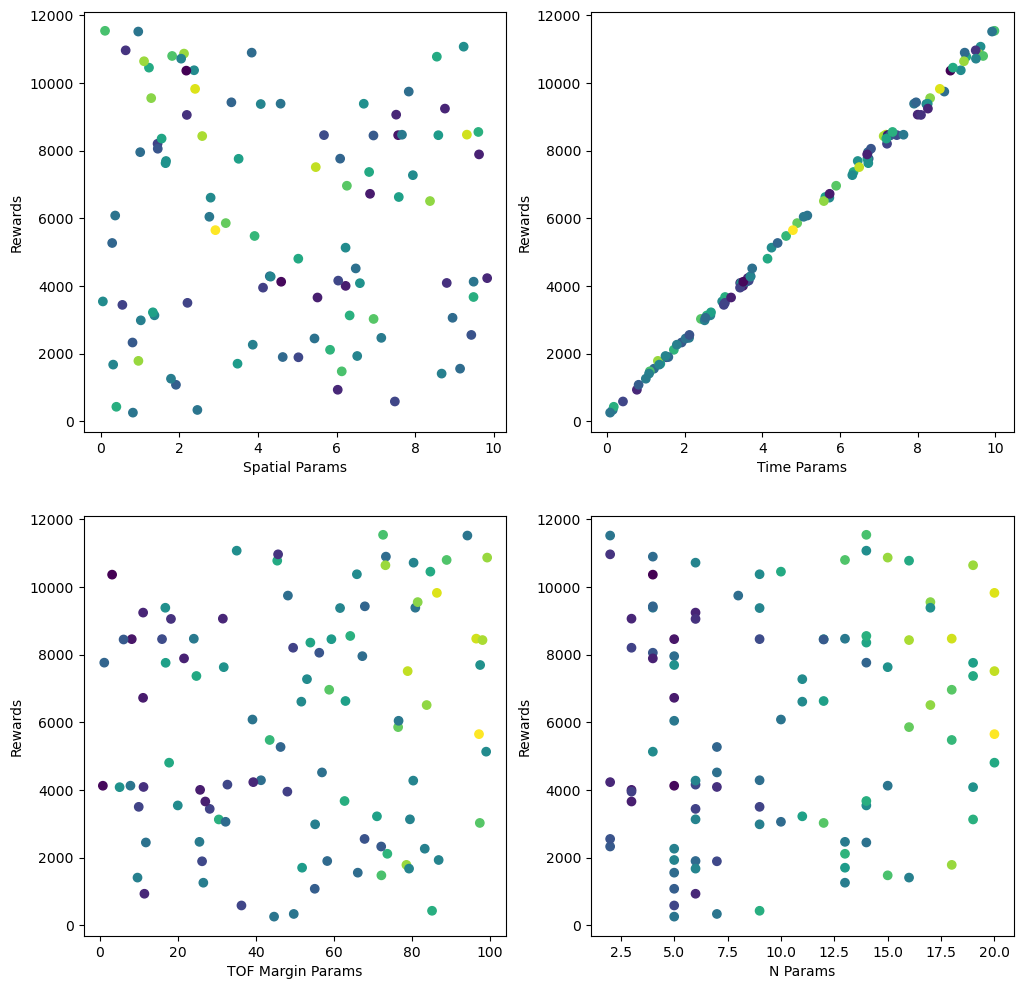

In [183]:
bandit.plot_rewards()

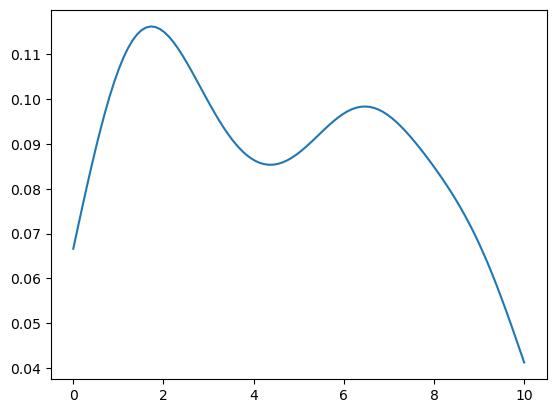

In [185]:
fig = plt.figure()
ax = fig.add_subplot(111)
grid = np.linspace(0,10,100)
ax.plot(grid, bandit.kde_spatial(grid))

<Axes: xlabel='tof_margin_params', ylabel='distances'>

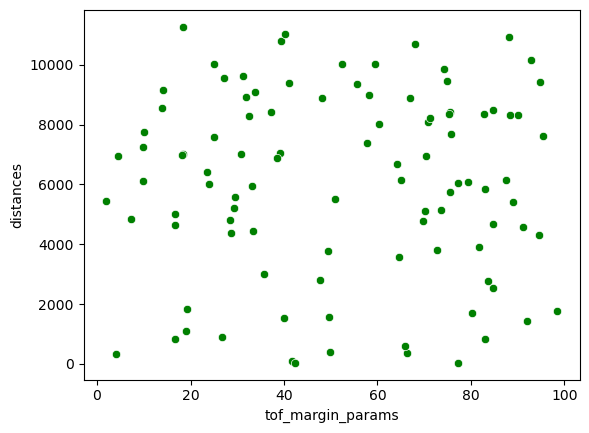

In [ ]:

sns.scatterplot(data, x = 'tof_margin_params', y='distances', color='green')


<Axes: xlabel='N_param', ylabel='distances'>

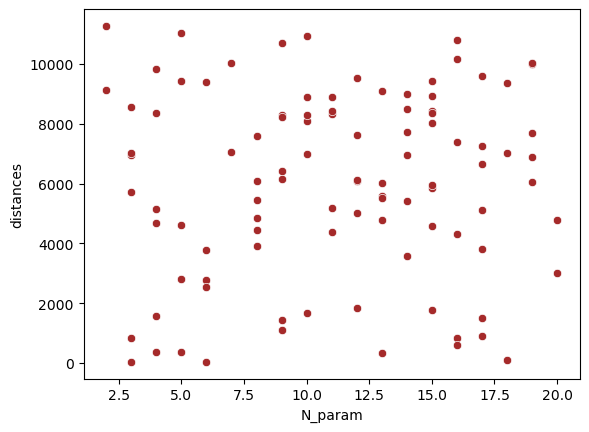

In [ ]:
sns.scatterplot(data, x = 'N_param', y = 'distances', color='brown')

<Axes: xlabel='spatial_params', ylabel='costs'>

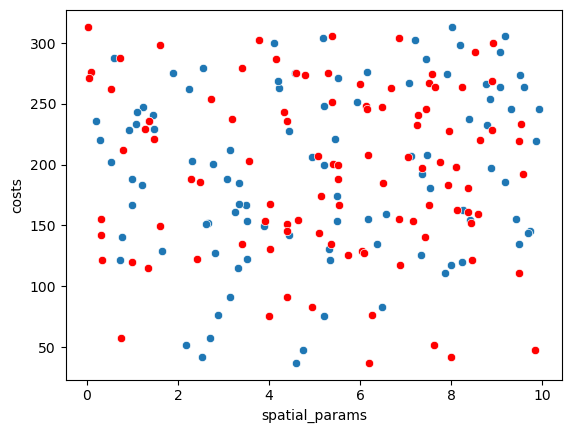

In [ ]:
sns.scatterplot(data, x = 'spatial_params', y = 'costs')
sns.scatterplot(data, x = 'time_params', y = 'costs', color='red')

<Axes: xlabel='spatial_params', ylabel='rewards'>

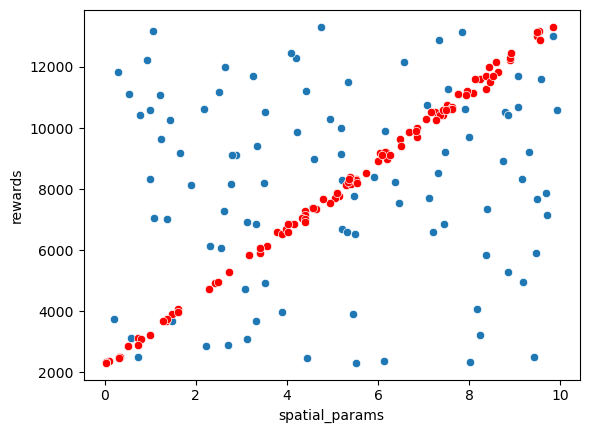

In [ ]:
sns.scatterplot(data, x = 'spatial_params', y = 'rewards')
sns.scatterplot(data, x = 'time_params', y = 'rewards', color='red')

<Axes: xlabel='N_param', ylabel='rewards'>

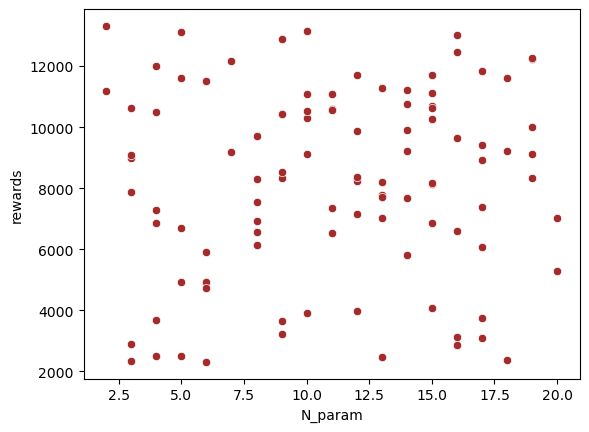

In [ ]:
sns.scatterplot(data, x = 'N_param', y = 'rewards', color='brown')

<Axes: xlabel='costs', ylabel='distances'>

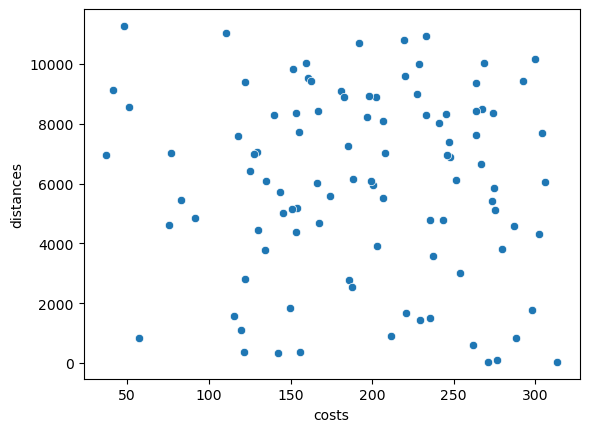

In [ ]:
sns.scatterplot(data, x='costs', y='distances')

Text(0.5, 0, 'delta_t_distance')

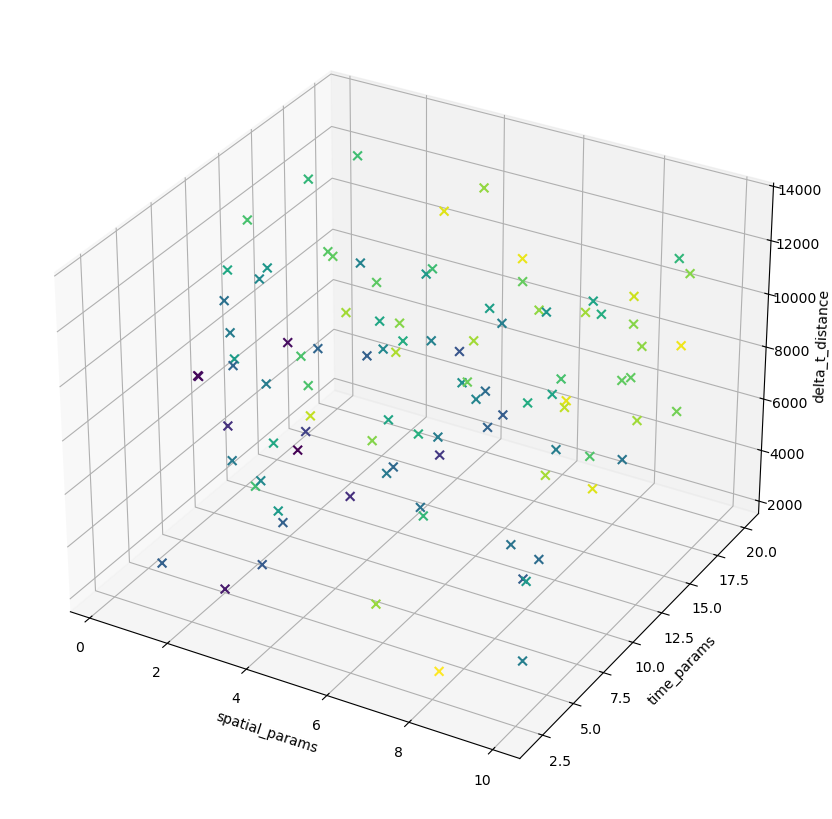

In [ ]:

import re, seaborn as sns
import numpy as np

from matplotlib import pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import ListedColormap


fig = plt.figure(figsize=(8,8))
ax = Axes3D(fig)
fig.add_axes(ax)

sc = ax.scatter(data['spatial_params'], data['N_param'], data['rewards'], c=data['costs'], s=40,  marker='x', alpha=1)
ax.set_xlabel('spatial_params')
ax.set_ylabel('time_params')
ax.set_zlabel('delta_t_distance')